# Crystal-field tomography, 2D toy, lattice-free cell field
Each voxel carries an amplitude for every flash cell (tilt, |g|) on a dense grid. Group TV over the cells should collect a grain's flashes on one region; an L1 term keeps the field sparse. No lattice. Every tenth tilt is held out. Inversions come from `run_cells.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

import sim2d
from invert_cells import group_tv, predict_field, true_field

## Data
Twinned particle of one phase with an amorphous cap at the same density, and the same particle without the cap.

In [2]:
sim2d.main("fewAm")
sim2d.main("fewA")
sims = {kind: np.load(f"runs/sim_{kind}.npz") for kind in ["fewAm", "fewA"]}
runs = {
    "fewAm": {
        "mean potential only": "sm_fewAm_meanonly",
        "cells, L1 5e-4": "cells_fewAm_g03",
        "cells, L1 5e-3": "cells_fewAm_l1_5e-3",
        "cells, L1 2e-2": "cells_fewAm_l1_2e-2",
    },
    "fewA": {
        "mean potential only": "sm_fewA_meanonly",
        "cells, L1 5e-4": "cells_fewA_g03",
    },
}
res = {kind: {name: np.load(f"runs/{f}.npz") for name, f in r.items()} for kind, r in runs.items()}

fewAm: 3011 atoms, 3 grains, 40 Friedel pairs, multislice 1.6 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewAm.npz


fewA: 3025 atoms, 3 grains, 60 Friedel pairs, multislice 1.7 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewA.npz


## Scores
Image error normalised by the data variance on train and held-out tilts. Density correlation with the true mean potential. Summed cell amplitude (crystal signal) in the crystal, the amorphous cap and outside the particle, and active cells per crystal voxel.

In [3]:
for kind, d in sims.items():
    data = d["I_coarse"]
    c = slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)
    var = data[:, c].var()
    held = np.arange(5, len(data), 10)
    train = np.setdiff1d(np.arange(len(data)), held)
    part = d["occ"].sum(0) > 0.5
    cryst = d["cryst"]
    print(kind)
    for name, r in res[kind].items():
        e = ((r["pred"] - data)[:, c] ** 2).mean(1) / var
        line = f"  {name:22s} train {e[train].mean():.3f}  held-out {e[held].mean():.3f}"
        line += f"  density corr {np.corrcoef(r['vbar'].ravel(), d['vbar'].ravel())[0, 1]:.3f}"
        if "a_sum" in r:
            s = r["a_sum"]
            amorph = part & (cryst < 0.5)
            line += f"  crystal signal: crystal {s[part & (cryst > 0.5)].mean():.2f}"
            line += f", amorphous {s[amorph].mean():.2f}" if amorph.any() else ""
            line += f", outside {s[~part].mean():.2f}"
            n_act = (r["a16"][:, part & (cryst > 0.5)] > 1e-3).sum(0).mean()
            line += f"  active cells {n_act:.0f}"
        print(line)

fewAm
  mean potential only    train 0.516  held-out 0.844  density corr 0.826
  cells, L1 5e-4         train 0.142  held-out 0.916  density corr 0.828  crystal signal: crystal 25.98, amorphous 41.65, outside 0.23  active cells 317


  cells, L1 5e-3         train 0.474  held-out 0.835  density corr 0.832  crystal signal: crystal 0.31, amorphous 0.40, outside 0.00  active cells 2
  cells, L1 2e-2         train 0.487  held-out 0.810  density corr 0.837  crystal signal: crystal 0.00, amorphous 0.00, outside 0.00  active cells 0
fewA
  mean potential only    train 0.694  held-out 1.133  density corr 0.846


  cells, L1 5e-4         train 0.168  held-out 1.511  density corr 0.838  crystal signal: crystal 30.60, outside 0.25  active cells 389


## Objective at the true cell field (diagnostic)
True reflections on the true grains with the true mean potential, as exact cells and snapped to the cell grid. Compared with what the inversion found at L1 5e-4.

In [4]:
d = sims["fewAm"]
r = res["fewAm"]["cells, L1 5e-4"]
data = d["I_coarse"]
c = slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)
var = data[:, c].var()
held = np.arange(5, len(data), 10)
train = np.setdiff1d(np.arange(len(data)), held)
truth = {}
for mode, snap in [("exact cells", False), ("snapped to grid", True)]:
    W, thc, uc = true_field(d, r["th_c"], r["u_c"], snap=snap)
    truth[mode] = (W, predict_field(d, d["vbar"], W, thc, uc))

In [5]:
import torch

for mode, (W, pred) in truth.items():
    e = ((pred - data)[:, c] ** 2).mean(1) / var
    line = f"true field, {mode:16s} train {e[train].mean():.3f}  held-out {e[held].mean():.3f}"
    if mode == "snapped to grid":
        line += f"  group TV {float(group_tv(W)):.3f}  L1 {float(W.sum(0).mean()):.2f}"
    print(line)
a = torch.as_tensor(r["a16"].astype(np.float32))
e = ((r["pred"] - data)[:, c] ** 2).mean(1) / var
print(f"found, L1 5e-4                 train {e[train].mean():.3f}  held-out {e[held].mean():.3f}"
      f"  group TV {float(group_tv(a)):.3f}  L1 {float(a.sum(0).mean()):.2f}")

true field, exact cells      train 0.358  held-out 0.592
true field, snapped to grid  train 0.404  held-out 0.719  group TV 0.046  L1 3.27
found, L1 5e-4                 train 0.142  held-out 0.916  group TV 0.391  L1 9.24


## All tilts, amorphous cap

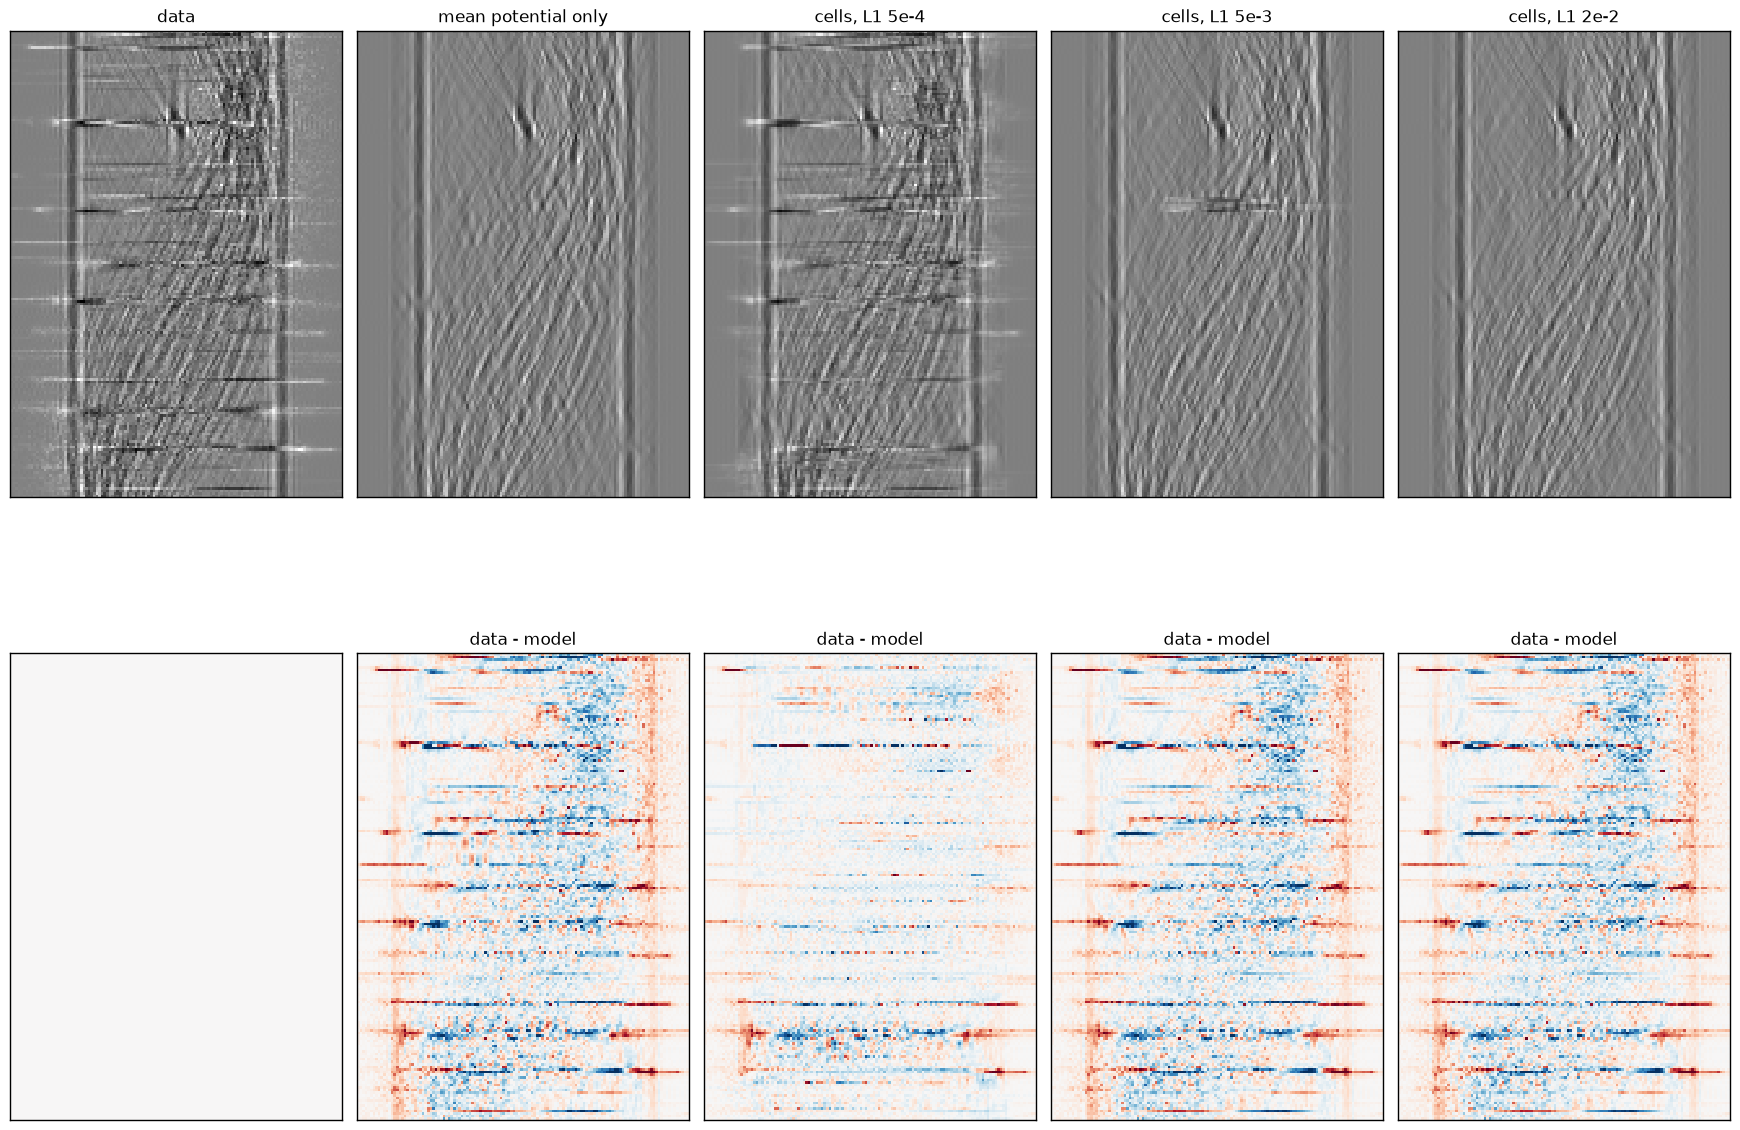

In [6]:
d = sims["fewAm"]
r = res["fewAm"]
data = d["I_coarse"]
crop = slice(data.shape[1] // 2 - 64, data.shape[1] // 2 + 64)
held = np.arange(5, len(data), 10)
names = list(r)
nc = len(names) + 1
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop]] + [r[n]["pred"][:, crop] for n in names],
        [np.zeros_like(data[:, crop])] + [data[:, crop] - r[n]["pred"][:, crop] for n in names],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data"] + names, [""] + ["data - model"] * len(names)],
    axsize=(3.5, 7),
);

## Held-out tilts, amorphous cap
Each held-out tilt is drawn six rows tall.

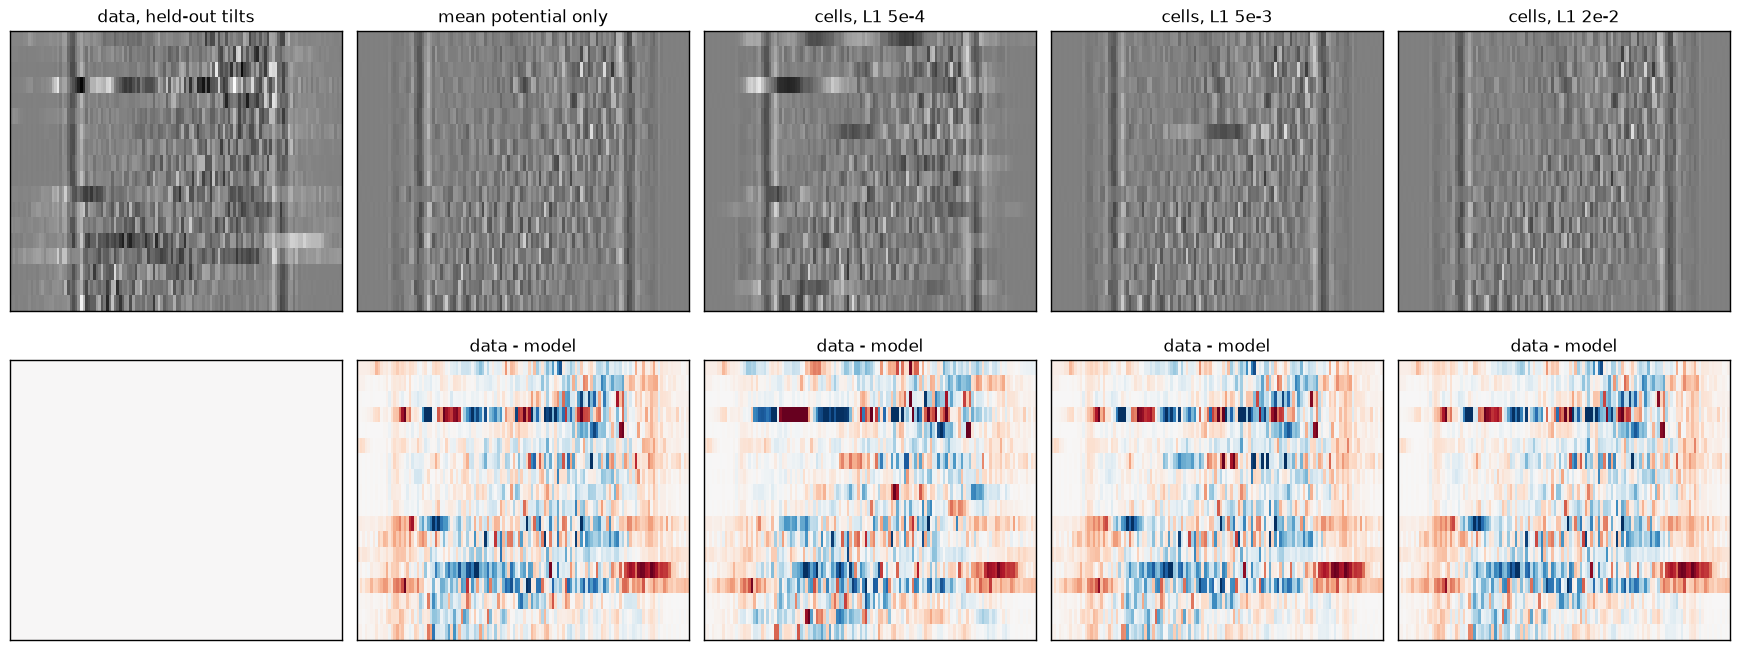

In [7]:
tall = lambda a: np.repeat(a[held][:, crop], 6, axis=0)
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in names],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in names],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data, held-out tilts"] + names, [""] + ["data - model"] * len(names)],
    axsize=(3.5, 3.5),
);

## Mean potential and crystal signal, amorphous cap

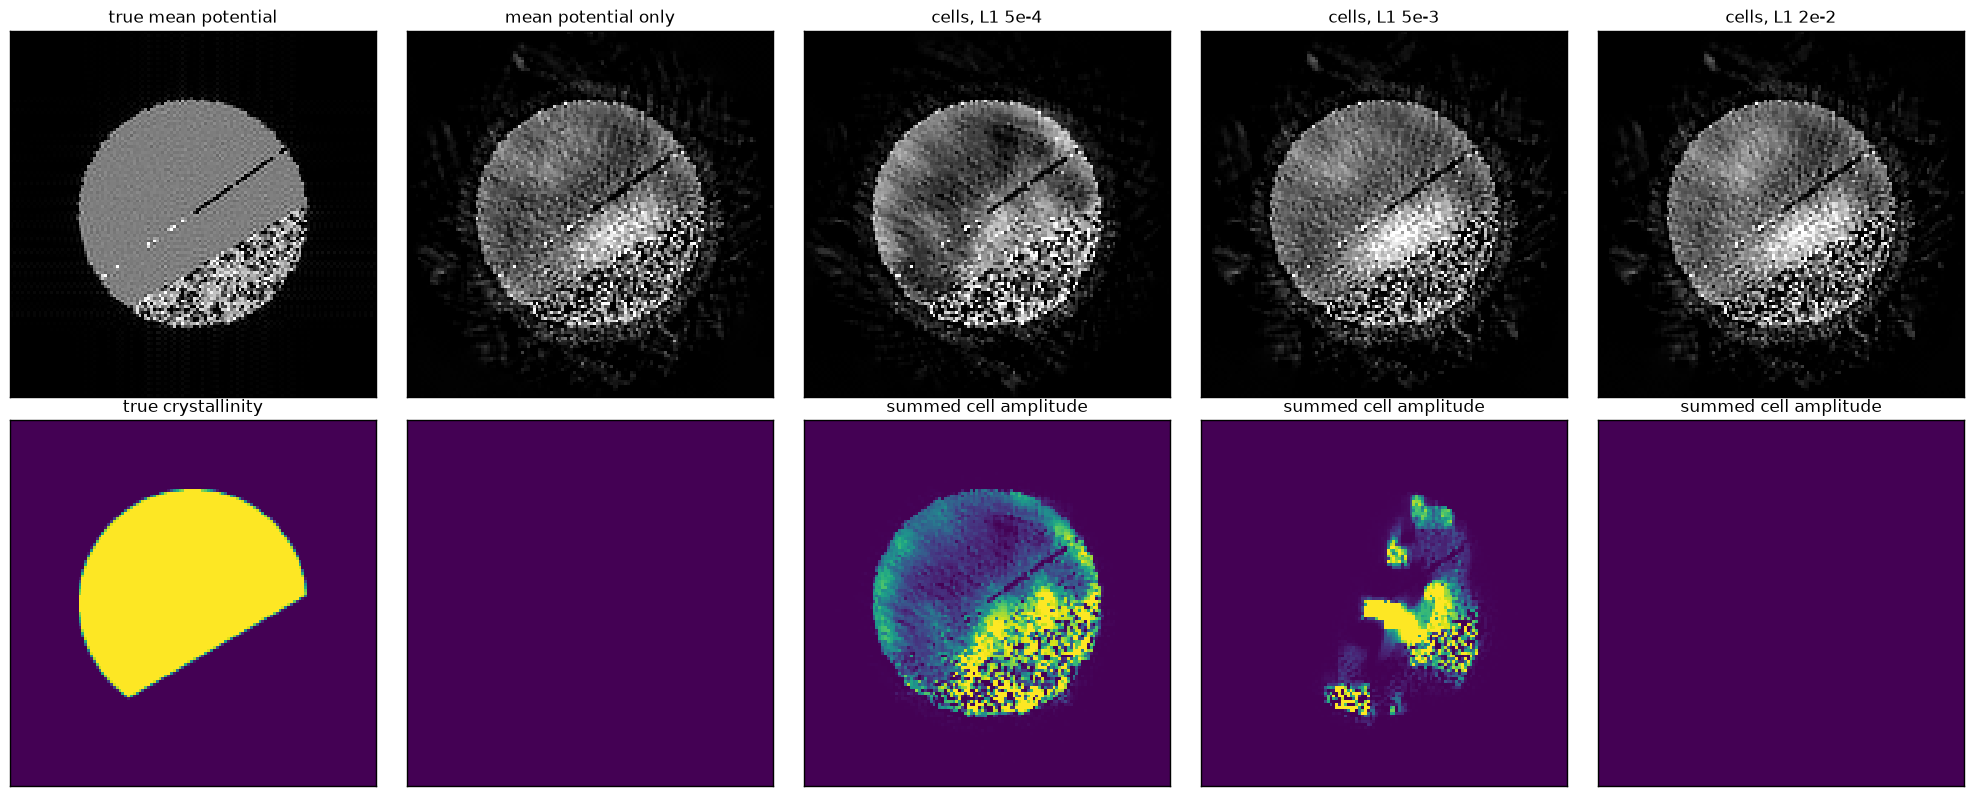

In [8]:
show_2d(
    [
        [np.flipud(d["vbar"].T)] + [np.flipud(r[n]["vbar"].T) for n in names],
        [np.flipud(d["cryst"].T), np.zeros_like(d["cryst"])] + [np.flipud(r[n]["a_sum"].T) for n in names[1:]],
    ],
    norm=[[{"interval_type": "manual", "vmin": 0.0, "vmax": 0.04}] * nc, [{"interval_type": "quantile"}] * nc],
    cmap=[["gray"] * nc, ["viridis"] * nc],
    title=[
        ["true mean potential"] + names,
        ["true crystallinity", ""] + ["summed cell amplitude"] * (len(names) - 1),
    ],
);

## Held-out tilts, no amorphous cap
Each held-out tilt is drawn six rows tall.

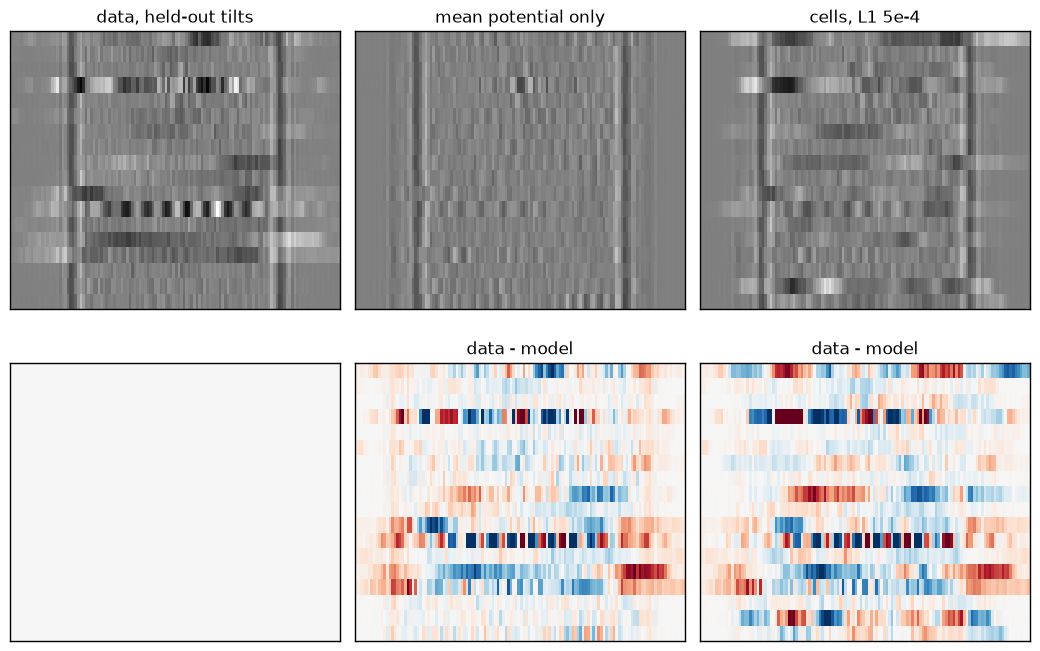

In [9]:
d = sims["fewA"]
r = res["fewA"]
data = d["I_coarse"]
names = list(r)
nc = len(names) + 1
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in names],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in names],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data, held-out tilts"] + names, [""] + ["data - model"] * len(names)],
    axsize=(3.5, 3.5),
);